In [1]:
import pandas as pd
import numpy as np

In [2]:
from qiime2 import Artifact

In [3]:
from skbio.stats import subsample_counts
from skbio.stats.distance import permanova
from skbio.stats.ordination import pcoa
from skbio.diversity import beta_diversity
from skbio import OrdinationResults, DistanceMatrix

In [4]:
from itertools import combinations

In [5]:
import seaborn as sns
from matplotlib import pyplot as plt
from statannot import add_stat_annotation

In [6]:
%matplotlib inline
sns.set(style='ticks')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'  # render SVG text as text, not curves
plt.rcParams['lines.markersize'] = 15

# PCOA plot function

In [7]:
def pcoa_plot(dist_mtx, metadata, column=None, title='', do_permanova=True, hue_order=None, **kwargs):
    print(f'Matrix={len(dist_mtx.ids)}, MD={len(metadata.index)}, column={column}')
    pc = pcoa(dist_mtx)
    if do_permanova:
        perm = permanova(dist_mtx, metadata, column)
    if hue_order:
        if column:
            used_hues = set(metadata[column].unique())
        else:
            used_hues = set(metadata.index)
        hue_order = [c for c in hue_order if c in used_hues]
    
    pc_df = pc.samples.join(metadata, how='inner')
    if column is None:
        pc_df = pc_df.reset_index()
        column = pc_df.columns[0]
    args = {
        'data': pc_df,
        'x':    'PC1',
        'y':    'PC2',
        'hue':  column,
    }
    args.update(kwargs)
    if hue_order:
        args['hue_order'] = hue_order
    ax = sns.relplot(**args)
    ax.set_axis_labels(
        f'PC1({pc.proportion_explained[0]:.2%})',
        f'PC2({pc.proportion_explained[1]:.2%})',
    )
    if do_permanova:
        plt.title(f'{title} [Permanova p={perm["p-value"]}]')
    else:
        plt.title(title)
    return ax, pc_df

# load metadata

In [8]:
md = pd.read_csv('stool.metagenomic.metadata.with_amyloid.tsv', sep='\t', index_col=0)
sorted(list(md.columns))

['TRF_start_age_mo',
 'TRF_start_date',
 'age_of_collection_days',
 'age_of_collection_months',
 'box',
 'brain_insoluble_ab40',
 'brain_insoluble_ab42',
 'brain_lysate_ab40',
 'brain_lysate_ab42',
 'brain_soluble_ab40',
 'brain_soluble_ab42',
 'cage_id',
 'collection_timepoint',
 'collection_timestamp',
 'dab_area_cortex',
 'dab_area_hippocampus',
 'dab_count_cortex',
 'dab_count_hippocampus',
 'date_of_collection',
 'description',
 'dna_extracted',
 'dob',
 'elevation',
 'empo_1',
 'empo_2',
 'empo_3',
 'env_biome',
 'env_feature',
 'env_material',
 'env_package',
 'feeding_condition',
 'genotype_diet',
 'geo_loc_name',
 'host_age',
 'host_age_units',
 'host_body_habitat',
 'host_body_product',
 'host_body_site',
 'host_common_name',
 'host_scientific_name',
 'host_subject_id',
 'host_taxid',
 'host_weight',
 'host_weight_units',
 'iacuc_institute',
 'iacuc_protocol_id',
 'katharoseq_cell_count',
 'katharoseq_community_type',
 'katharoseq_control_type',
 'katharoseq_plate_number',
 '

In [9]:
md.drop([r for r in md.index if 'BLANK' in r], inplace=True)

In [10]:
md['genotype_diet'] = md.mouse_genotype + "." + md.feeding_condition
md.genotype_diet.value_counts()

Tg.ALF     53
Tg.TRF     50
Ntg.ALF    42
Name: genotype_diet, dtype: int64

In [11]:
genotype_diet_order = ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF']
genotype_diet_groups = [
    ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF'],
    ['Ntg.ALF', 'Tg.ALF'],
    ['Tg.ALF', 'Tg.TRF'],
]
genotype_diet_palette = {
    'Tg.ALF': 'purple',
    'Ntg.ALF': 'orange',
    'Tg.TRF': 'green',
}

In [12]:
sex_order = ('male', 'female')
sex_markers = {'male': 'o', 'female': 'D'}

In [13]:
md['zt_time'] = md.zt_collection_time.str.replace('ZT','', regex=False).astype(int)
md['zt_collection_time'] = 'ZT' + md.zt_time.astype(str).str.zfill(2)
md.zt_collection_time.unique()

array(['ZT08', 'ZT20', 'ZT12', 'ZT16', 'ZT00', 'ZT04'], dtype=object)

In [14]:
md.head()

,title,empo_1,empo_2,empo_3,latitude,taxon_id,elevation,env_biome,longitude,description,...,serum_ab40_ab42_ratio,serum_ab42_ab40_ratio,brain_lysate_ab40,brain_lysate_ab42,brain_insoluble_ab40,brain_insoluble_ab42,brain_soluble_ab40,brain_soluble_ab42,genotype_diet,zt_time
sample_name,,,,,,,,,,,,,,,,,,,,,
14708.332.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,18.073368,0.055330,406.741573,27.528090,80300.239234,20058.612440,406.741573,27.528090,Tg.ALF,8
14708.314.T20.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,3.468113,0.288341,460.338983,32.881356,46088.495575,16899.705015,460.338983,32.881356,Tg.ALF,20
14708.320.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,8
14708.319.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Tg.ALF,12
14708.322.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,16


# Genome counts

In [15]:
genome_counts = Artifact.load('metagenomic/159171_rs210_per_genome.feature-table.qza').view(pd.DataFrame)

In [16]:
genome_counts.info()

<class 'pandas.core.frame.DataFrame'>
Index: 161 entries, 14708.329.T16.S to 14708.323.T20.S
Columns: 12853 entries, G000001985 to G920984865
dtypes: float64(12853)
memory usage: 15.8+ MB


In [17]:
# no blanks
genome_counts.drop([c for c in genome_counts.index if 'BLANK' in c], inplace=True)

In [18]:
genome_counts.T.sum().describe()

count    1.450000e+02
mean     2.543018e+06
std      1.650659e+06
min      6.483440e+05
25%      1.327753e+06
50%      2.299963e+06
75%      2.990590e+06
max      9.682784e+06
dtype: float64

In [19]:
# rarefaction
genome_int = genome_counts.apply(
    result_type='expand',
    func=lambda x: x.round().astype(int)
)

limit = genome_int.sum(axis=1).min()
print(limit)

genome_all_rarefy = genome_int.apply(
    axis='columns', 
    result_type='expand',
    func=lambda x: subsample_counts(x, limit, replace=True)
)
genome_all_rarefy.columns = genome_int.columns
genome_all_rarefy.T.sum().describe()

648344


count       145.0
mean     648344.0
std           0.0
min      648344.0
25%      648344.0
50%      648344.0
75%      648344.0
max      648344.0
dtype: float64

In [20]:
genome_all_rarefy.drop(
    genome_all_rarefy.T[genome_all_rarefy.sum() ==0].index, 
    axis=1,
    inplace=True,
)

In [21]:
md.loc[genome_all_rarefy.index].genotype_diet.value_counts()

Tg.ALF     53
Tg.TRF     50
Ntg.ALF    42
Name: genotype_diet, dtype: int64

In [22]:
genome_all_dist = beta_diversity('braycurtis', genome_all_rarefy, ids=genome_all_rarefy.index)

# Plots

## all groups for all timepoints

Matrix=145, MD=145, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.15997339793413107 and the largest is 2.720563339247766.
  warn(


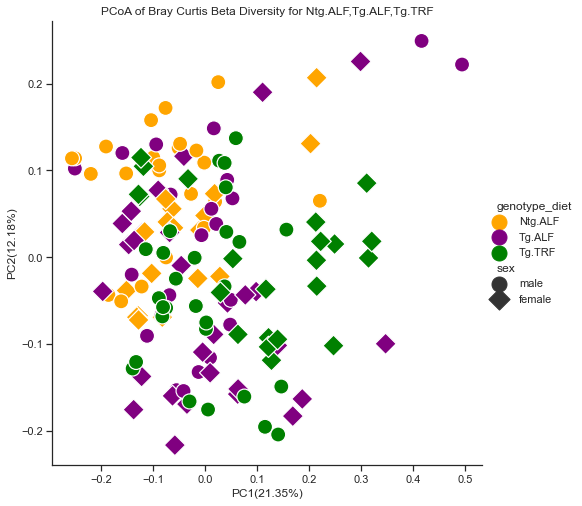

Matrix=95, MD=95, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.10935044009289474 and the largest is 1.8833675097817215.
  warn(


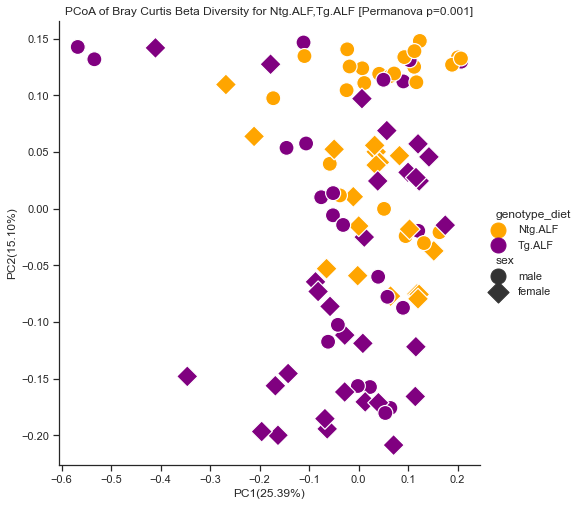

Matrix=103, MD=103, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.12922664006578832 and the largest is 2.028284243723808.
  warn(


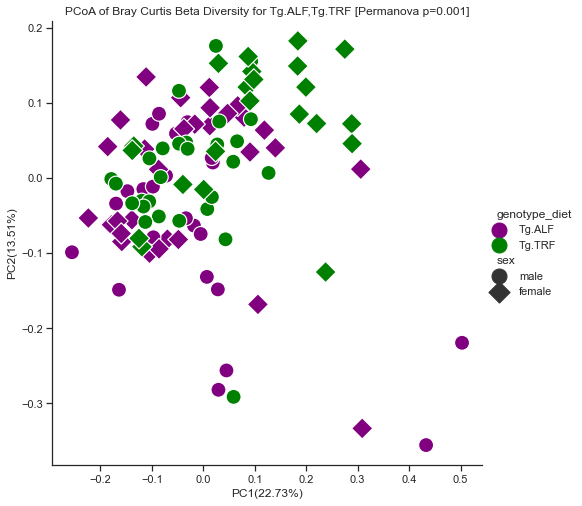

In [23]:
for g in genotype_diet_groups:
    sub_md = md[md.genotype_diet.isin(g)]
    sub_dist = genome_all_dist.filter(sub_md.index)
    do_perm = len(g)==2
    pcoa_plot(
        sub_dist, 
        sub_md, 
        'genotype_diet',
        do_permanova=do_perm,
        hue_order=genotype_diet_order,
        palette=genotype_diet_palette,
        title=f"PCoA of Bray Curtis Beta Diversity for {','.join(g)}",
        style='sex',
        markers=sex_markers,
        height=7,
    )
    # plt.tight_layout()
    plt.savefig(f'images/metagenomic.bray_curtis_pcoa.{".".join(g)}.svg')
    plt.show()

## Per-sex

Matrix=75, MD=75, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.10352813785394718 and the largest is 1.279066569163946.
  warn(


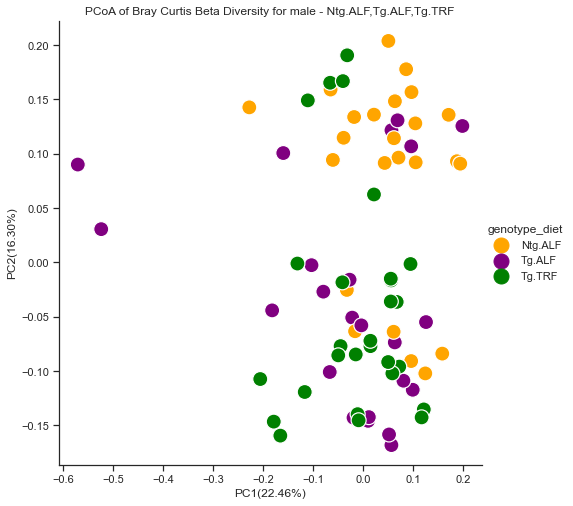

Matrix=47, MD=47, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.06947679308306269 and the largest is 1.081161867757136.
  warn(


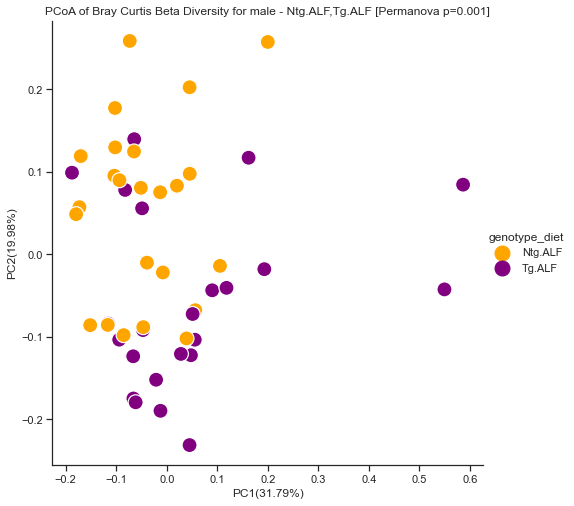

Matrix=51, MD=51, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.07023708937717761 and the largest is 1.0334198251788766.
  warn(


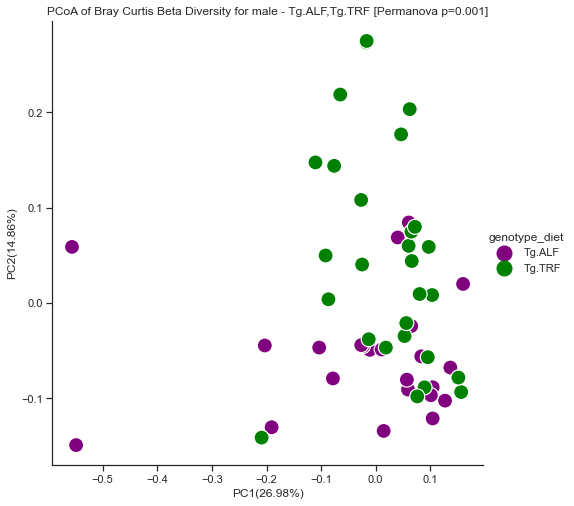

Matrix=70, MD=70, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.07444123478768525 and the largest is 1.524703813358934.
  warn(


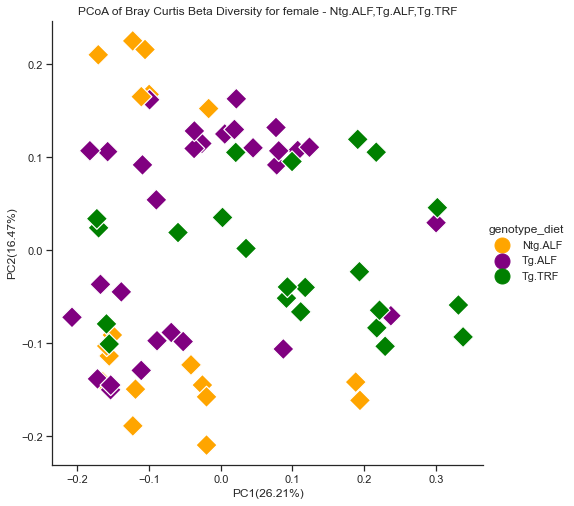

Matrix=48, MD=48, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.044209865360659066 and the largest is 0.8794969270747939.
  warn(


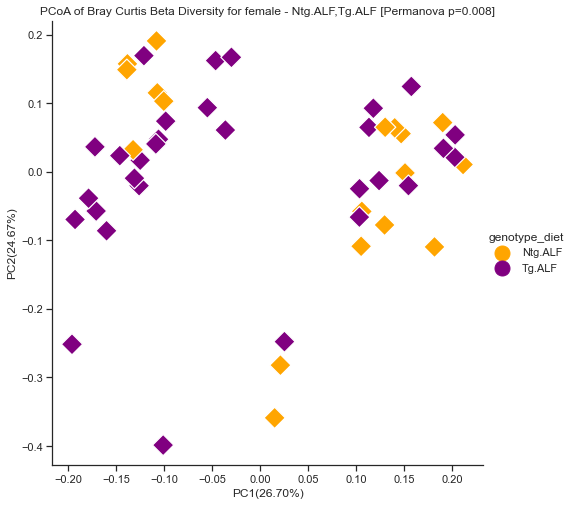

Matrix=52, MD=52, column=genotype_diet


/opt/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:143: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.053851962834524134 and the largest is 1.2284586653826477.
  warn(


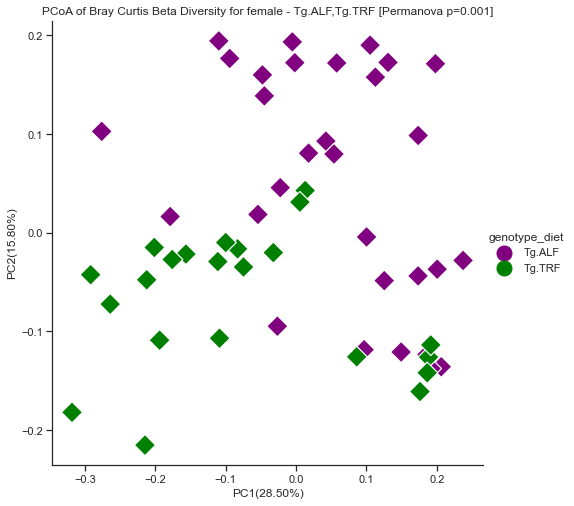

In [24]:
for sex in sex_order:
    for g in genotype_diet_groups:
        sub_md = md[
            (md.genotype_diet.isin(g)) &
            (md.sex == sex)
        ]
        sub_dist = genome_all_dist.filter(sub_md.index)
        do_perm = len(g)==2
        pcoa_plot(
            sub_dist, 
            sub_md, 
            'genotype_diet',
            do_permanova=do_perm,
            hue_order=genotype_diet_order,
            palette=genotype_diet_palette,
            title=f"PCoA of Bray Curtis Beta Diversity for {sex} - {','.join(g)}",
            height=7,
            marker=sex_markers[sex],
        )
        # plt.tight_layout()
        plt.savefig(f'images/metagenomic.bray_curtis_pcoa.{sex}.{".".join(g)}.svg')

        plt.show()